# Seasonal ARIMA on hourly energy load

Follow the lesson's executable date choices: train from 1 November through
29 December 2014, and test the final 48 hours. The prose elsewhere describes
different months, so the precise dates below define this experiment.
A separate [assignment notebook](assignment.ipynb) uses fresh Nile data.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_error
from sklearn.preprocessing import MinMaxScaler
from statsmodels.tsa.statespace.sarimax import SARIMAX

energy = pd.read_csv('../../../7-TimeSeries/data/energy.csv', parse_dates=['timestamp']).set_index('timestamp').asfreq('h')
train = energy.loc['2014-11-01':'2014-12-29', ['load']]
test = energy.loc['2014-12-30':'2014-12-31', ['load']]
assert train.shape == (1416, 1) and test.shape == (48, 1)
assert train.index.max() < test.index.min() and train.load.gt(0).all() and test.load.gt(0).all()
scaler = MinMaxScaler().fit(train)
scaled_train = pd.Series(scaler.transform(train).ravel(), index=train.index, name='load')
scaled_test = pd.Series(scaler.transform(test).ravel(), index=test.index, name='load')
np.testing.assert_allclose(scaler.inverse_transform(scaled_train.to_numpy().reshape(-1, 1)).ravel(), train.load)
display(pd.DataFrame({'rows':[len(train),len(test)], 'first':[train.index[0],test.index[0]],
                      'last':[train.index[-1],test.index[-1]]}, index=['train','test']))

,rows,first,last
train,1416,2014-11-01,2014-12-29 23:00:00
test,48,2014-12-30,2014-12-31 23:00:00


In [2]:
model = SARIMAX(scaled_train, order=(4,1,0), seasonal_order=(1,1,0,24),
                enforce_stationarity=False, enforce_invertibility=False)
fitted = model.fit(disp=False, maxiter=300)
assert fitted.mle_retvals['converged']
print(fitted.summary())

                                     SARIMAX Results                                      
Dep. Variable:                               load   No. Observations:                 1416
Model:             SARIMAX(4, 1, 0)x(1, 1, 0, 24)   Log Likelihood                3403.203
Date:                            Sun, 18 Oct 2026   AIC                          -6794.405
Time:                                    21:26:19   BIC                          -6763.101
Sample:                                11-01-2014   HQIC                         -6782.687
                                     - 12-29-2014                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8460      0.016     51.498      0.000       0.814       0.878
ar.L2         -0.5278      0.035   

## Rolling origins with horizons one, two, and three

At each origin, forecast the next three hours before revealing the next
actual observation. Update the state with that observation, keeping the
fitted coefficients fixed. This is expanding-history state updating, not
a claim that the parameters were re-estimated at every origin. The
persistence and 24-hour seasonal baselines use information available at
that same origin.

In [3]:
records = []
current = fitted
for origin in range(len(test) - 2):
    prediction = scaler.inverse_transform(current.forecast(3).to_numpy().reshape(-1,1)).ravel()
    origin_time = train.index[-1] if origin == 0 else test.index[origin-1]
    for horizon in range(1,4):
        target_time = test.index[origin+horizon-1]
        assert target_time > origin_time
        records.append({'origin': origin_time, 'timestamp': target_time, 'horizon': horizon,
                        'actual': float(test.loc[target_time, 'load']),
                        'prediction': float(prediction[horizon-1]),
                        'persistence': float(energy.loc[origin_time, 'load']),
                        'daily_naive': float(energy.loc[target_time-pd.Timedelta(hours=24), 'load'])})
    current = current.append(scaled_test.iloc[[origin]], refit=False)
forecasts = pd.DataFrame(records)
assert len(forecasts) == 46 * 3
denominator = train.load.diff(24).abs().dropna().mean()
metrics = []
for horizon, group in forecasts.groupby('horizon'):
    for name in ['prediction','persistence','daily_naive']:
        metrics.append({'horizon': horizon, 'method': name,
                        'MAPE_percent': 100*mean_absolute_percentage_error(group.actual, group[name]),
                        'MAE': mean_absolute_error(group.actual, group[name]),
                        'RMSE': root_mean_squared_error(group.actual, group[name]),
                        'MASE': mean_absolute_error(group.actual,group[name])/denominator})
metrics = pd.DataFrame(metrics)
display(metrics.round(4))
forecasts.to_csv('energy-forecasts.csv', index=False)
metrics.to_csv('energy-metrics.csv', index=False)

,horizon,method,MAPE_percent,MAE,RMSE,MASE
0,1,prediction,0.5690,21.3962,27.0319,0.1344
1,1,persistence,3.4318,126.3478,159.7600,0.7938
2,1,daily_naive,4.3264,152.1739,173.2909,0.9560
3,2,prediction,1.2317,46.4443,58.7306,0.2918
4,2,persistence,6.5698,242.2609,302.8350,1.5220
5,2,daily_naive,4.1180,146.0870,165.6770,0.9178
6,3,prediction,1.6909,64.1597,88.5628,0.4031
7,3,persistence,9.3886,345.2609,425.7242,2.1691
8,3,daily_naive,3.8840,139.3043,157.7929,0.8752


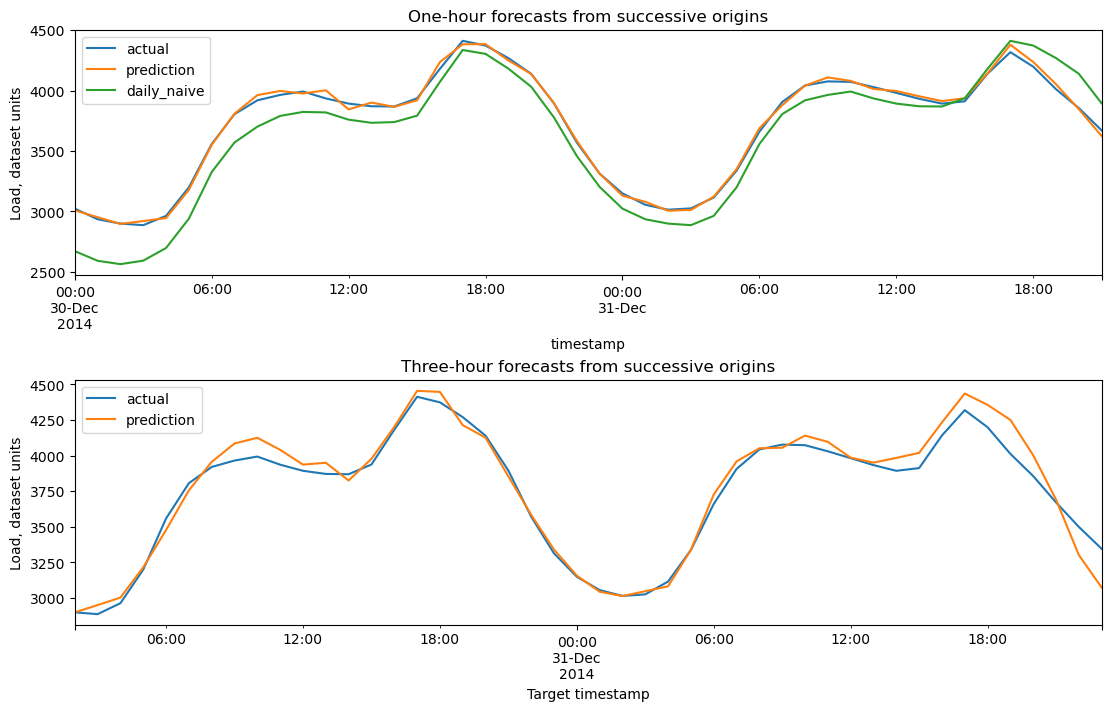

In [4]:
one_hour = forecasts.loc[forecasts.horizon.eq(1)].set_index('timestamp')
three_hour = forecasts.loc[forecasts.horizon.eq(3)].set_index('timestamp')
fig, axes = plt.subplots(2,1,figsize=(11,7),layout='constrained')
one_hour[['actual','prediction','daily_naive']].plot(ax=axes[0])
axes[0].set(title='One-hour forecasts from successive origins', ylabel='Load, dataset units')
three_hour[['actual','prediction']].plot(ax=axes[1])
axes[1].set(title='Three-hour forecasts from successive origins', ylabel='Load, dataset units', xlabel='Target timestamp')
fig.savefig('arima-energy.png', dpi=150)
plt.show()

## Challenge: accuracy measures and limits

MAPE is reported in percent after undoing scaling. Its denominator makes it
unsuitable at zero actuals and unstable near zero. MAE keeps the target's
units. RMSE gives large errors more weight. MASE divides MAE by the mean
absolute 24-hour seasonal difference in the training set; values below one
compare favourably with that training scale, not necessarily with the test
baseline's measured error. Compare methods at the same horizon and origins.

The held-out window is short and overlaps adjacent rolling forecasts, so
errors are dependent and do not establish year-round reliability. The
model's parameters were fixed before testing. Differencing can help remove
a trend or seasonal pattern, but does not guarantee stationarity. ARIMA's
moving-average terms model past innovations, rather than a rolling mean
of the observed target. See [Forecasting: Principles and Practice](https://otexts.com/fpp3/accuracy.html).